# 01 - Data Preparation

使用 PySpark 对 KuaiRec small_matrix 进行全量数据处理：
- 数据加载与 Schema 检查
- 数据清洗
- 标签生成（`watch_ratio > 2` → `label=1`）
- 基础统计 EDA
- 按用户采样（300用户），输出 Parquet 供后续使用

In [1]:
import os
import sys

# 解决 PyTorch/LightGBM 与 PySpark 的 OpenMP 冲突
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'
os.environ['PYSPARK_PYTHON'] = sys.executable
os.environ['PYSPARK_DRIVER_PYTHON'] = sys.executable

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
spark = SparkSession.builder \
    .appName("KuaiRec_DataPrep") \
    .master("local[*]") \
    .config("spark.driver.memory", "4g") \
    .getOrCreate()

spark.sparkContext.setLogLevel("WARN")
print(f"Spark version: {spark.version}")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/05 04:32:23 WARN Utils: Your hostname, NormcoredeMacBook-Air.local, resolves to a loopback address: 127.0.0.1; using 192.168.1.221 instead (on interface en0)
26/11/05 04:32:23 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/05 04:32:23 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark version: 4.2.0


## 1. 数据加载

In [3]:
DATA_DIR = "./data/KuaiRec/data"

df = spark.read.csv(f"{DATA_DIR}/small_matrix.csv", header=True, inferSchema=True)
df.printSchema()

root
 |-- user_id: integer (nullable = true)
 |-- video_id: integer (nullable = true)
 |-- play_duration: integer (nullable = true)
 |-- video_duration: integer (nullable = true)
 |-- time: timestamp (nullable = true)
 |-- date: double (nullable = true)
 |-- timestamp: double (nullable = true)
 |-- watch_ratio: double (nullable = true)



In [4]:
df.show(5, truncate=False)

+-------+--------+-------------+--------------+-----------------------+-----------+----------------+------------------+
|user_id|video_id|play_duration|video_duration|time                   |date       |timestamp       |watch_ratio       |
+-------+--------+-------------+--------------+-----------------------+-----------+----------------+------------------+
|14     |148     |4381         |6067          |2020-07-05 05:27:48.378|2.0200705E7|1.593898068378E9|0.7221031811438932|
|14     |183     |11635        |6100          |2020-07-05 05:28:00.057|2.0200705E7|1.593898080057E9|1.907377049180328 |
|14     |3649    |22422        |10867         |2020-07-05 05:29:09.479|2.0200705E7|1.593898149479E9|2.063310941382166 |
|14     |5262    |4479         |7908          |2020-07-05 05:30:43.285|2.0200705E7|1.593898243285E9|0.5663884673748103|
|14     |8234    |4602         |11000         |2020-07-05 05:35:43.459|2.0200705E7|1.593898543459E9|0.4183636363636364|
+-------+--------+-------------+--------

## 2. 基础统计

In [5]:
total_rows = df.count()
n_users = df.select('user_id').distinct().count()
n_videos = df.select('video_id').distinct().count()

print(f"Total interactions : {total_rows:,}")
print(f"Unique users        : {n_users:,}")
print(f"Unique videos       : {n_videos:,}")
print(f"Matrix density      : {total_rows / (n_users * n_videos):.2%}")

Total interactions : 4,676,570
Unique users        : 1,411
Unique videos       : 3,327
Matrix density      : 99.62%


In [6]:
# watch_ratio 分布统计
df.select(
    F.min('watch_ratio').alias('min'),
    F.max('watch_ratio').alias('max'),
    F.mean('watch_ratio').alias('mean'),
    F.percentile_approx('watch_ratio', 0.5).alias('p50'),
    F.percentile_approx('watch_ratio', 0.75).alias('p75'),
    F.percentile_approx('watch_ratio', 0.9).alias('p90'),
    F.percentile_approx('watch_ratio', 0.95).alias('p95'),
    F.percentile_approx('watch_ratio', 0.99).alias('p99'),
).show()

+---+-----------------+------------------+------------------+------------------+------------------+------------------+------------------+
|min|              max|              mean|               p50|               p75|               p90|               p95|               p99|
+---+-----------------+------------------+------------------+------------------+------------------+------------------+------------------+
|0.0|571.5214280603849|0.9070694783381374|0.7691502720803683|1.1205470387118122|1.5586607263399488|1.9536400493566013|3.5791580400276053|
+---+-----------------+------------------+------------------+------------------+------------------+------------------+------------------+



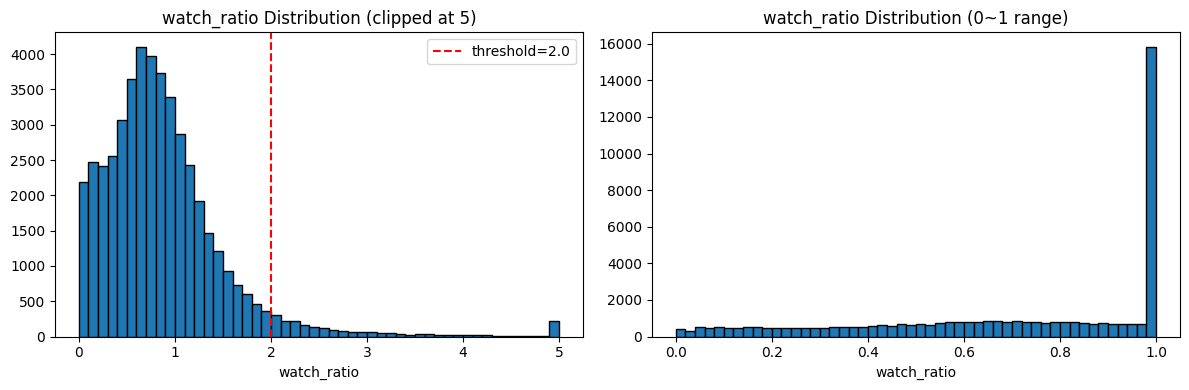

In [7]:
# watch_ratio 分布可视化（采样避免内存压力）
sample_pdf = df.select('watch_ratio').sample(fraction=0.01, seed=42).toPandas()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(sample_pdf['watch_ratio'].clip(0, 5), bins=50, edgecolor='black')
axes[0].set_title('watch_ratio Distribution (clipped at 5)')
axes[0].set_xlabel('watch_ratio')
axes[0].axvline(x=2.0, color='red', linestyle='--', label='threshold=2.0')
axes[0].legend()

axes[1].hist(sample_pdf['watch_ratio'].clip(0, 1), bins=50, edgecolor='black')
axes[1].set_title('watch_ratio Distribution (0~1 range)')
axes[1].set_xlabel('watch_ratio')

plt.tight_layout()
plt.show()

## 3. 数据清洗

In [8]:
# 检查缺失值
null_counts = df.select([
    F.count(F.when(F.col(c).isNull(), c)).alias(c)
    for c in df.columns
])
null_counts.show()

+-------+--------+-------------+--------------+------+------+---------+-----------+
|user_id|video_id|play_duration|video_duration|  time|  date|timestamp|watch_ratio|
+-------+--------+-------------+--------------+------+------+---------+-----------+
|      0|       0|            0|             0|181992|181992|   181992|          0|
+-------+--------+-------------+--------------+------+------+---------+-----------+



In [9]:
# 清洗规则：
# 1. watch_ratio 不为空
# 2. video_duration > 0（排除时长异常视频）
# 3. watch_ratio >= 0（排除异常负值）
df_clean = df.filter(
    F.col('watch_ratio').isNotNull() &
    F.col('video_duration').isNotNull() &
    (F.col('video_duration') > 0) &
    (F.col('watch_ratio') >= 0)
)

dropped = total_rows - df_clean.count()
print(f"Dropped {dropped:,} rows ({dropped/total_rows:.2%})")
print(f"Clean dataset: {df_clean.count():,} rows")

Dropped 0 rows (0.00%)
Clean dataset: 4,676,570 rows


## 4. 标签生成

参考 KuaiRec 官方文档及相关文献（Batch-Adaptive Doubly Robust Learning, 2024），
将 `watch_ratio > 2` 定义为正样本（用户循环播放超过2遍，视为强满意信号）。

在 CVR 预测框架下：
- **Click** = watch 行为（曝光 → 播放）
- **Conversion** = `watch_ratio > 2`（播放 → 深度满意）

In [10]:
LABEL_THRESHOLD = 2.0

df_labeled = df_clean.withColumn(
    'label',
    F.when(F.col('watch_ratio') > LABEL_THRESHOLD, 1).otherwise(0)
)

# 标签分布
label_dist = df_labeled.groupBy('label').count().orderBy('label')
label_dist.show()

pos_count = df_labeled.filter(F.col('label') == 1).count()
total_count = df_labeled.count()
print(f"Positive rate: {pos_count/total_count:.2%}")

+-----+-------+
|label|  count|
+-----+-------+
|    0|4459395|
|    1| 217175|
+-----+-------+

Positive rate: 4.64%


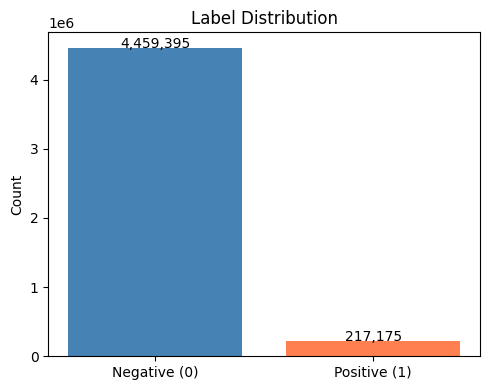

In [11]:
# 标签分布可视化
label_pdf = label_dist.toPandas()
plt.figure(figsize=(5, 4))
plt.bar(['Negative (0)', 'Positive (1)'], label_pdf['count'], color=['steelblue', 'coral'])
plt.title('Label Distribution')
plt.ylabel('Count')
for i, v in enumerate(label_pdf['count']):
    plt.text(i, v + 1000, f'{v:,}', ha='center')
plt.tight_layout()
plt.show()

## 5. 按用户采样

取前300个用户的全部交互记录（约100万行），保留用户行为的完整性。
相比随机行采样，按用户采样不会破坏用户历史序列，计算用户统计特征时不会出现偏差。

In [12]:
N_USERS = 300

sampled_users = [
    row.user_id
    for row in df_labeled.select('user_id').distinct().orderBy('user_id').limit(N_USERS).collect()
]

df_sampled = df_labeled.filter(F.col('user_id').isin(sampled_users))

sampled_rows = df_sampled.count()
print(f"Sampled users       : {N_USERS}")
print(f"Sampled interactions: {sampled_rows:,}")
print(f"Positive rate       : {df_sampled.filter(F.col('label')==1).count()/sampled_rows:.2%}")

Sampled users       : 300
Sampled interactions: 994,389
Positive rate       : 4.85%


## 6. 保存结果

In [13]:
OUTPUT_PATH = "./data/processed/interactions_sampled.parquet"

df_sampled.write.mode('overwrite').parquet(OUTPUT_PATH)
print(f"Saved to {OUTPUT_PATH}")

spark.stop()
print("Spark session stopped.")

Saved to ./data/processed/interactions_sampled.parquet
Spark session stopped.
